# Reusing microscopy images with IIIF
### 4TU.ResearchData · Hands-on workshop · Google Colab

**Research question:** How can we inspect, annotate and computationally highlight cells in microscopy images without downloading the entire dataset?


## 1. Discover a reusable dataset

Open the [sample dataset in 4TU.ResearchData sandbox](https://next.data.4tu.nl/datasets/5d40e250-23bd-4a79-9626-6c9d6003c747): https://edu.nl/3bdn4


Read its description, methods, licence and file  list. What kind of microscopy is used? 



In [3]:
## Reading a manifest from 4TU.ResearchData

import requests
import json

base = "https://next.data.4tu.nl"
dataset_uuid = "5d40e250-23bd-4a79-9626-6c9d6003c747"
manifest_url = f"{base}/iiif/v3/{dataset_uuid}/1/manifest"

response = requests.get(manifest_url, timeout=60)
response.raise_for_status()
original = response.json()
print(manifest_url)
print(list(original))

https://next.data.4tu.nl/iiif/v3/5d40e250-23bd-4a79-9626-6c9d6003c747/1/manifest
['@context', 'id', 'type', 'label', 'metadata', 'thumbnail', 'items']


### Read the manifest like a viewer
The Presentation API describes what to display. A Canvas is a coordinate space; its painting annotation connects an image to that space. An Image API service provides image derivatives and zoom tiles. A Canvas is not necessarily identical in dimensions to its source image.

In the editor compare the manifest title, metadata and Canvas list with the raw JSON (Preview dropdown → Raw Manifest, if available).

In [4]:
print("Title:", original.get("label"))
print("Metadata:", original.get("metadata"))
print("Number of canvases:", len(original["items"]))
canvas = original["items"][0]


Title: {'en': ["IIIF Manifest for 'Microscopy raw and processed data to measure cell size and  cell death '."]}
Metadata: [{'label': {'en': ['Authors']}, 'value': {'none': ['Leila Iñigo de la Cruz']}}, {'label': {'en': ['Description']}, 'value': {'en': ['The data contains  BrightField Microscopy images that were taken on the strains bem1::KanMx pGal-Cdc42-sfGFP,bem1bem3::CloNAT pGal-Cdc42-sfGFP,pGal-Cdc42-sfGFP, and WT. The goal was to measure the cell sizes as a proxy of the polarization state for those strains in specific galactose concentrations taken by the population growth results.  We use three galactose concentrations : 0%, 0.06%, and 0.1%. %=w/vAll microscopy was performed with a Nikon Eclipse Ti-E inverted microscope with an oil immersion 60x objective,1.40 of numerical aperture, and a refractive index of 1.51. The software used for data collection was Nis-Elements Ar (https://www.microscope.healthcare.nikon.com/products/software/nis-elements/nis-elements-advanced-research) v

## 4. Discover image file UUIDs with the repository API

The repository API returns file metadata. The IIIF Image API serves image derivatives. These are different APIs.

Production pattern: `https://data.4tu.nl/v2/articles/<dataset_uuid>/files` and `https://data.4tu.nl/iiif/v3/<file_uuid>`.

For this sandbox dataset we consistently use `next.data.4tu.nl` instead; do not assume a sandbox file UUID exists in production.

Check here the [4TU.ResearchData documentation](data.4tu/nl/api/docs)

In [5]:
files_url = f"{base}/v2/articles/{dataset_uuid}/files"
print(files_url)
response = requests.get(files_url, timeout=60)
response.raise_for_status()
file_list = response.json()
print(json.dumps(file_list, indent=2)[:500])

https://next.data.4tu.nl/v2/articles/5d40e250-23bd-4a79-9626-6c9d6003c747/files


[
  {
    "id": null,
    "uuid": "8140014d-303b-4f9f-a26b-9291a3dfbffc",
    "name": "Exp_3_WT_pGal_0%_Transmitted387.tif",
    "size": 538722,
    "is_link_only": false,
    "is_incomplete": false,
    "download_url": "https://next.data.4tu.nl/file/5d40e250-23bd-4a79-9626-6c9d6003c747/8140014d-303b-4f9f-a26b-9291a3dfbffc",
    "supplied_md5": null,
    "computed_md5": "8d33f0ed5f2ffcd82dd7d18014f8ed2f"
  },
  {
    "id": null,
    "uuid": "f8b055a3-8019-49fe-a8af-f1c6d186aca7",
    "name": "Ex


In [6]:
# Inspect file names and identifiers before choosing an image.
for i, item in enumerate(file_list[0:3]):
    print(i, item.get("name"), item.get("uuid"),  item.get("size")/1000, "KB")

0 Exp_3_WT_pGal_0%_Transmitted387.tif 8140014d-303b-4f9f-a26b-9291a3dfbffc 538.722 KB
1 Exp_3_WT_pGal_0%_Transmitted388.tif f8b055a3-8019-49fe-a8af-f1c6d186aca7 538.722 KB
2 Exp_3_WT_pGal_0%_Transmitted389.tif 66672178-e5ee-47b1-94d7-d8af4ceafe4b 538.722 KB


## Check that the Image API endpoint construction works

In [7]:
from uuid import UUID

image_index = 0  # CHANGE to the index of a microscopy image above
file_record = file_list[image_index]
file_uuid = file_record.get("uuid") or file_record.get("id")
file_uuid = str(UUID(str(file_uuid)))  # verify that it is a UUID

iiif_base = f"{base}/iiif/v3/{file_uuid}"
print(iiif_base)
response = requests.get(f"{iiif_base}/info.json", timeout=60)
response.raise_for_status()
info = response.json()
print(json.dumps(info, indent=2))

https://next.data.4tu.nl/iiif/v3/8140014d-303b-4f9f-a26b-9291a3dfbffc
{
  "@context": "http://iiif.io/api/image/3/context.json",
  "id": "https://next.data.4tu.nl/iiif/v3/8140014d-303b-4f9f-a26b-9291a3dfbffc",
  "type": "ImageService3",
  "protocol": "http://iiif.io/api/image",
  "profile": "level1",
  "width": 512,
  "height": 512,
  "maxWidth": 512,
  "maxHeight": 512,
  "maxArea": 262144,
  "extraFormats": [
    "jpg",
    "png",
    "tif",
    "webp"
  ],
  "extraFeatures": [
    "cors",
    "mirroring",
    "regionByPx",
    "regionSquare",
    "rotationArbitrary",
    "rotationBy90s"
  ],
  "tiles": [
    {
      "width": 1024,
      "height": 1024,
      "scaleFactors": [
        1
      ]
    }
  ],
  "sizes": [
    {
      "width": 512,
      "height": 512
    }
  ]
}


## 5. Retrieve an image with Python
Image API URL anatomy: `{service}/{region}/{size}/{rotation}/{quality}.{format}`. `full` means the entire image area; `800,` asks for width 800 with proportional height. Check `info.json` for dimensions, profile, supported sizes and extra features. Percentage cropping is not assumed to be supported.

We use a bounded preview first. If arbitrary resizing is unsupported, use a size advertised in `sizes`.

https://next.data.4tu.nl/iiif/v3/8140014d-303b-4f9f-a26b-9291a3dfbffc/full/512,/0/default.jpg
Returned size: (512, 512)


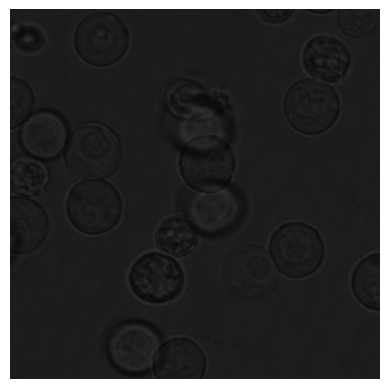

In [8]:
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

region = "full"
size = f"{min(800, info['width'])},"
rotation = "0"
quality_format = "default.jpg"
image_url = f"{iiif_base}/{region}/{size}/{rotation}/{quality_format}"
print(image_url)
response = requests.get(image_url, timeout=60)
response.raise_for_status()
image = Image.open(BytesIO(response.content)).convert("RGB")
print("Returned size:", image.size)
plt.imshow(image)
plt.axis("off");

## 6. Highlight candidate cells with Python
This is an exploratory segmentation exercise, not a validated cell viability assay. We use intensity thresholding, remove small objects and label connected regions. It works best for cells that contrast with the background. If the image has multiple fluorescence channels, inspect the experimental description before choosing a channel; the JPEG is a rendered derivative, not necessarily quantitative raw microscopy data.

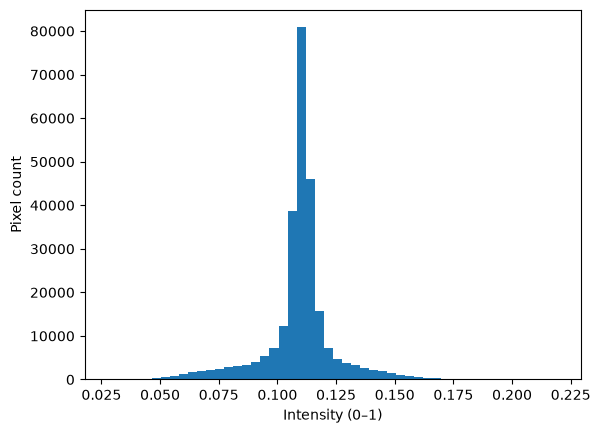

In [10]:
from skimage import color, filters, morphology, measure
import numpy as np

analysis_image = np.asarray(roi if "roi" in globals() else image)
gray = color.rgb2gray(analysis_image)
plt.hist(gray.ravel(), bins=50)
plt.xlabel("Intensity (0–1)")
plt.ylabel("Pixel count");

/tmp/ipykernel_186063/2888404586.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, min_size=30)
/tmp/ipykernel_186063/2888404586.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_holes(mask, area_threshold=30)


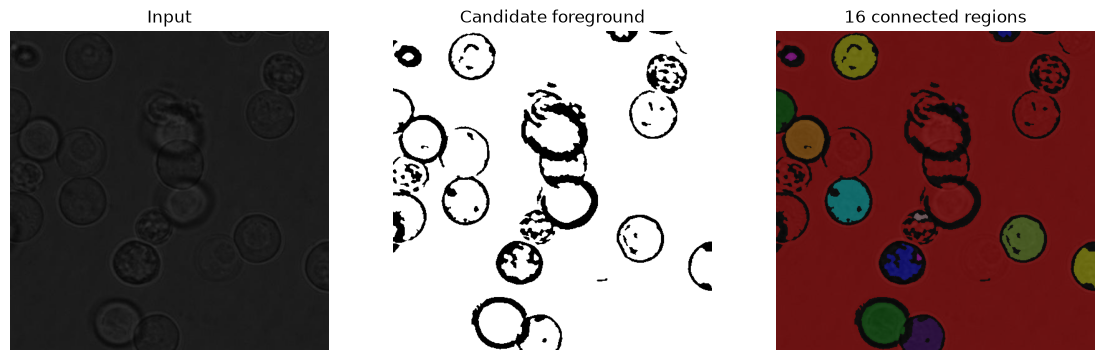

In [11]:
# Adjust polarity and threshold after looking at the image and histogram.
bright_cells = True
smoothed = filters.gaussian(gray, sigma=1)
threshold = filters.threshold_otsu(smoothed)
mask = smoothed > threshold if bright_cells else smoothed < threshold
mask = morphology.remove_small_objects(mask, min_size=30)
mask = morphology.remove_small_holes(mask, area_threshold=30)
labels = measure.label(mask)
regions = measure.regionprops(labels)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(analysis_image)
axes[0].set_title("Input")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Candidate foreground")
axes[2].imshow(color.label2rgb(labels, image=gray, bg_label=0, alpha=0.35))
axes[2].set_title(f"{len(regions)} connected regions")
for ax in axes:
    ax.axis("off")
plt.show()

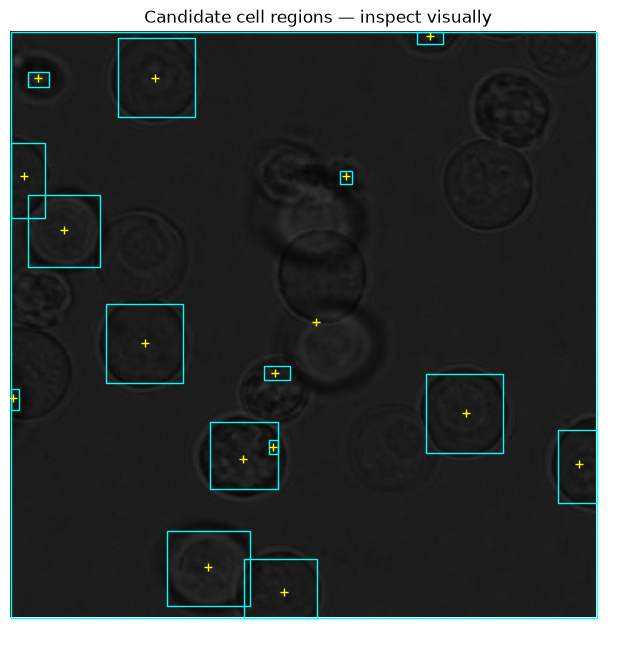

In [12]:
# Overlay bounding boxes and centres of candidate regions.
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(analysis_image)
for region in regions:
    y0, x0, y1, x1 = region.bbox
    cy, cx = region.centroid
    ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False,
                           edgecolor="cyan", linewidth=1))
    ax.plot(cx, cy, "+", color="yellow")
ax.set_title("Candidate cell regions — inspect visually")
ax.axis("off");

**Interpretation:** Change `bright_cells`, smoothing and minimum region size. Which cells are missed? Which objects are merged? Compare with your manual annotations if you chose the same image and region. Connected regions are not necessarily individual cells; touching cells, debris and uneven illumination can bias counts. No physical size or viability can be inferred without calibration and experimental evidence.

### Wrap-up
What is reusable here? The original image service, the derived manifest with manual annotations, and the analysis code. To translate computational detections back into IIIF annotations, account for crop offsets, resizing and the mapping between source-image and Canvas coordinates before constructing targets. That is a possible next step, not required for this session.

**References:** [IIIF Presentation API 3](https://iiif.io/api/presentation/3.0/) · [IIIF Image API 3](https://iiif.io/api/image/3.0/) · [4TU API documentation](https://data.4tu.nl/api/docs?urls.primaryName=v2) · [Digirati annotation documentation](https://manifest-editor-docs.netlify.app/docs/creating-annotations).

**Instructor preflight:** The sandbox dataset, manifest and file endpoint could not be retrieved during notebook preparation. Verify that they work from Colab, confirm the file list schema, select a suitable microscopy image and test the image requests and segmentation parameters before delivery. The code does not substitute a different dataset or claim experimentally validated results.